# Анализ пользовательской воронки и потерь конверсии

## 1. Постановка задачи

### Бизнес-контекст

Сервис авиабилетов Т-Банка позволяет пользователям искать, выбирать и приобретать авиабилеты внутри банковской экосистемы.

Однако не каждая пользовательская сессия завершается покупкой. При этом отсутствие покупки в рамках одной сессии не обязательно означает потерю клиента. Пользователь может прервать поиск, сравнить предложения и вернуться к оформлению позднее.

### Бизнес-проблема

Необходимо определить, какие этапы и сценарии пользовательского пути связаны с наибольшими потерями конверсии, а также выяснить, насколько часто пользователи возвращаются к покупке после незавершённых сессий.

### Цель исследования

Исследовать поведение пользователей сервиса авиабилетов, выявить проблемные участки воронки и сформулировать обоснованные гипотезы по повышению конверсии в покупку.

In [1]:
import pandas as pd

## 2. Загрузка данных и подготовка к анализу

### 2.1. Загрузка данных

В исследовании используется открытый датасет «Т-Банк: воронка авиабилетов», опубликованный в рамках олимпиады DANO 2025-2026.

Более подробно про датасет можно прочитать тут: https://dano.hse.ru/mirror/pubs/share/1102777960.pdf.

In [2]:
url = 'https://dano.hse.ru/mirror/pubs/share/1103375613.xlsx'

excel_file = pd.ExcelFile(url)
excel_file.sheet_names

['Данные']

In [3]:
df = pd.read_excel(excel_file)

df.shape

(244345, 22)

In [4]:
df.head()

,session_start_dt,device_platform,client_start_year,client_id,session_id,session_source,session_channel,screen_nm,screen_dttm,client_avia_user_start_year,...,client_gmv,session_purchase_price,session_purchase_tickets_num,session_purchase_tickets_sourse,session_purchase_status,session_purchase_tickets_airline,session_purchase_tickets_departure,session_purchase_tickets_arrival,session_purchase_tickets_luggage_flg,session_purchase_tickets_class_of_service
0,2025-08-11,android,2022.0,1ced90f0cbf7673a49e1f06035a20c2d31bd2876e768f2...,168e64115c5eb71efa3f2ffb59a38a04f182540de70312...,Контент-каналы,Сторис,Оффер,2025-08-11 13:05:44.638,2025,...,27427.476667,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2025-04-10,ios,2016.0,707572ff842ece6fd9c6ab59c5f7d7309de18ae153995b...,a1e18971d51f0e7699396daa17b8373dd2bddec4ffa2da...,Неизвестно,Неизвестно,Оффер,2025-04-10 23:55:10.936,2024,...,72363.028889,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2025-06-05,ios,2025.0,514278f8446c5920e20faddc6aa5b03cc8fa784aa9be9a...,f29b5c0c7391fb9aee4bb47d9dab77d1161e1eec5b108f...,SEO,Bing,Выдача,2025-06-05 10:23:44.627,2025,...,6645.640000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2025-02-18,android,2022.0,d42de563a20cd93b6218c5eab57aac2f62e8a6ffaec3d1...,9abb7f52910e38152f4e261157fd4435534dbf7273f080...,SEO,Яндекс,Поиск,2025-02-18 15:21:08.491,2024,...,3543.480000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2025-09-01,ios,2022.0,fb3597c695c46ebe63eb6f8ff9e89b7cd0fc74a6c309fe...,a6a3488345af3d422b8bf2b11c14f1aa75c4829c606179...,Неизвестно,Неизвестно,Выдача,2025-09-01 11:35:23.627,2024,...,22816.832000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244345 entries, 0 to 244344
Data columns (total 22 columns):
 #   Column                                     Non-Null Count   Dtype  
---  ------                                     --------------   -----  
 0   session_start_dt                           244345 non-null  object 
 1   device_platform                            244134 non-null  object 
 2   client_start_year                          244300 non-null  float64
 3   client_id                                  244345 non-null  object 
 4   session_id                                 244345 non-null  object 
 5   session_source                             244345 non-null  object 
 6   session_channel                            244345 non-null  object 
 7   screen_nm                                  244345 non-null  object 
 8   screen_dttm                                244345 non-null  object 
 9   client_avia_user_start_year                244345 non-null  int64  
 10  client_s

Приводим дату к типу даты.

In [6]:
df['session_start_dt'] = pd.to_datetime(df['session_start_dt'])
df['screen_dttm'] = pd.to_datetime(df['screen_dttm'])

Определяем количество уникальных объектов и общий объём наблюдений.

In [7]:
print('Количество событий:', len(df))
print('Уникальных пользователей:', df['client_id'].nunique())
print('Уникальных сессий:', df['session_id'].nunique())
print('Уникальных экранов:', df['screen_nm'].nunique())

Количество событий: 244345
Уникальных пользователей: 1900
Уникальных сессий: 38561
Уникальных экранов: 6


Изучаем распределение числа событий на сессию.

In [8]:
events_per_session = df.groupby('session_id').size()

events_per_session.describe()

,0
count,38561.000000
mean,6.336584
std,9.366966
min,1.000000
25%,2.000000
50%,4.000000
75%,7.000000
max,405.000000


Получаем список экранов и частоту их посещения.

In [9]:
df['screen_nm'].value_counts()

,count
screen_nm,
Выдача,110591
Поиск,59525
Оффер,53172
Чекаут,15836
Покупка бэк,2789
Покупка фронт,2432


**Вывод:**
Датасет содержит 244 345 событий, относящихся к 1 900 пользователям и 38 561 сессии. Всего представлено шесть типов экранов.

Среднее количество событий на сессию составляет 6,34, медианное - 4. Максимальное значение достигает 405 событий, что указывает на наличие сессий с необычно большим числом взаимодействий.

Наиболее распространёнными событиями являются посещения экранов «Выдача», «Поиск» и «Оффер».

Поскольку в одной сессии экран может посещаться несколько раз, количество событий нельзя напрямую использовать для расчёта конверсии. В дальнейшем продуктовые метрики будут рассчитываться на уровне уникальных сессий или пользователей.

### 2.2. Качество данных

Перед построением пользовательской воронки проверим наличие дубликатов, корректность связи между сессиями и пользователями, а также полноту заполнения признаков.

In [10]:
missing_pct = df.isna().mean().mul(100).round(2)

missing_pct.sort_values(ascending=False)

,0
session_purchase_tickets_airline,98.93
session_purchase_status,98.93
session_purchase_tickets_luggage_flg,98.93
session_purchase_tickets_arrival,98.93
session_purchase_tickets_class_of_service,98.93
session_purchase_tickets_departure,98.93
session_purchase_tickets_sourse,98.93
session_purchase_price,98.86
session_purchase_tickets_num,98.86
device_platform,0.09


Проверяем наличие полностью одинаковых записей и корректность связи между сессиями и пользователями.

In [11]:
print('Полных дубликатов:', df.duplicated().sum())
print('Сессий с несколькими клиентами:', df.groupby('session_id')['client_id'].nunique().gt(1).sum())

Полных дубликатов: 0
Сессий с несколькими клиентами: 0


**Вывод:** Проверка не выявила полных дубликатов строк и сессий, связанных с несколькими пользователями.

Пропущенные значения преимущественно сосредоточены в признаках покупки. Согласно документации, сведения о стоимости и количестве билетов заполняются при успешном оформлении заказа, поэтому отсутствие этих значений не обязательно свидетельствует об ошибке.

### 2.3. Определение успешной покупки

Для последующего анализа конверсии необходимо определить, какие сессии завершились покупкой авиабилетов.

Согласно документации, поле `session_purchase_price` заполняется при успешном оформлении заказа.

В данных также присутствует поле `session_purchase_status`, принимающее значение «Успешные». Проверим согласованность двух признаков на уровне уникальных сессий, чтобы выбрать единое правило определения покупки.

Создаём два признака покупки, агрегированных на уровне сессии.

In [12]:
purchase_flags = df['session_purchase_price'].notna().groupby(df['session_id']).any()
status_flags = df['session_purchase_status'].eq('Успешные').groupby(df['session_id']).any()

Сравниваем признаки и определяем, насколько согласованно они фиксируют покупку.

In [13]:
pd.crosstab(purchase_flags, status_flags)

session_purchase_status,False,True
session_purchase_price,,
False,36054,0
True,143,2364


**Вывод:**
Из 2 507 сессий с заполненной стоимостью покупки в 2 364 также присутствует статус «Успешные».

В оставшихся 143 сессиях стоимость заполнена, однако статус «Успешные» не зафиксирован. Обратных случаев, когда успешный статус присутствует без стоимости покупки, не обнаружено.

Таким образом, использование только поля статуса привело бы к исключению части успешных сессий.

В качестве основного признака покупки выбрано наличие значения в `session_purchase_price`.

### 2.4. Проверка согласованности событий покупки

В датасете присутствуют два события: «Покупка фронт» и «Покупка бэк».

Документация не раскрывает их точного назначения, поэтому перед построением пользовательской воронки необходимо проверить, как эти события связаны с подтверждённой покупкой и в каком порядке они фиксируются.

Создаём таблицу наличия событий покупки в каждой сессии и сопоставляем их с признаком `purchased`.

In [14]:
screen_presence = pd.crosstab(df['session_id'], df['screen_nm']).gt(0)

purchase_audit = screen_presence[['Покупка фронт', 'Покупка бэк']].copy()
purchase_audit['purchased'] = purchase_flags

Проверяем, совпадает ли наличие бэкенд-события с подтверждённой покупкой.

In [15]:
pd.crosstab(purchase_audit['Покупка бэк'], purchase_audit['purchased'], margins=True)

purchased,False,True,All
Покупка бэк,,,
False,36054,0,36054
True,0,2507,2507
All,36054,2507,38561


Аналогично для фронт-события.

In [16]:
pd.crosstab(purchase_audit['Покупка фронт'], purchase_audit['purchased'], margins=True)

purchased,False,True,All
Покупка фронт,,,
False,36051,257,36308
True,3,2250,2253
All,36054,2507,38561


Для каждой сессии определяем время первого появления фронтенд- и бэкенд-событий.

In [17]:
final_events = df[df['screen_nm'].isin(['Покупка фронт', 'Покупка бэк'])]
first_final_times = final_events.groupby(['session_id', 'screen_nm'])['screen_dttm'].min().unstack()

Проверяем фактический порядок первого появления событий в сессиях, где есть оба события.

In [18]:
both_events = first_final_times.dropna()

print('Фронт раньше бэка:', (both_events['Покупка фронт'] < both_events['Покупка бэк']).sum())
print('Бэк раньше фронта:', (both_events['Покупка бэк'] < both_events['Покупка фронт']).sum())
print('Время совпадает:', (both_events['Покупка фронт'] == both_events['Покупка бэк']).sum())

Фронт раньше бэка: 11
Бэк раньше фронта: 2239
Время совпадает: 0


**Вывод:**

В 2 507 сессиях зафиксировано событие «Покупка бэк», которое полностью совпадает с признаком успешной покупки по наличию стоимости заказа.

Событие «Покупка фронт» присутствует в 2 250 успешных сессиях, отсутствует в 257 и встречается в 3 сессиях без подтверждённой покупки. При этом в 99,5% сессий с обоими событиями «Покупка бэк» фиксируется раньше «Покупка фронт».

Таким образом, **«Покупка фронт» не является обязательным этапом успешной покупки**. Для дальнейшего анализа используем признак `purchased`, а события фронтенда и бэкенда не рассматриваем как последовательные этапы пользовательской воронки. Их точное техническое назначение неизвестно.

### 2.5. Подготовка рабочей таблицы

Исходный датасет содержит отдельные события посещения экранов. Однако для анализа конверсии и сравнения пользовательских сессий необходима таблица, в которой каждая строка соответствует одной сессии.

Сформируем такую таблицу, сохранив идентификатор пользователя, дату начала сессии и признак успешной покупки.

Проверяем, сколько сессий имеют разные даты начала в своих событиях.

In [19]:
df.groupby('session_id')['session_start_dt'].nunique().gt(1).sum()

np.int64(0)

In [20]:
sessions = df[['session_id', 'client_id', 'session_start_dt']].drop_duplicates('session_id').copy()

In [21]:
sessions['purchased'] = sessions['session_id'].map(purchase_flags)

sessions.head()

,session_id,client_id,session_start_dt,purchased
0,168e64115c5eb71efa3f2ffb59a38a04f182540de70312...,1ced90f0cbf7673a49e1f06035a20c2d31bd2876e768f2...,2025-08-11,False
1,a1e18971d51f0e7699396daa17b8373dd2bddec4ffa2da...,707572ff842ece6fd9c6ab59c5f7d7309de18ae153995b...,2025-04-10,True
2,f29b5c0c7391fb9aee4bb47d9dab77d1161e1eec5b108f...,514278f8446c5920e20faddc6aa5b03cc8fa784aa9be9a...,2025-06-05,True
3,9abb7f52910e38152f4e261157fd4435534dbf7273f080...,d42de563a20cd93b6218c5eab57aac2f62e8a6ffaec3d1...,2025-02-18,False
4,a6a3488345af3d422b8bf2b11c14f1aa75c4829c606179...,fb3597c695c46ebe63eb6f8ff9e89b7cd0fc74a6c309fe...,2025-09-01,False


Проверяем размер полученной таблицы и распределение целевого признака.

In [22]:
print('Сессий:', len(sessions))
print('Сессий с покупкой:', sessions['purchased'].sum())
print('Сессий без покупки:', (~sessions['purchased']).sum())

Сессий: 38561
Сессий с покупкой: 2507
Сессий без покупки: 36054


### Выводы по подготовке данных

Для дальнейшего исследования подготовлены две таблицы:

- `df` - исходные события пользовательских сессий, необходимые для анализа последовательностей экранов.
- `sessions` - уникальные пользовательские сессии с бинарным признаком покупки.

В качестве признака успешной покупки выбран `purchased`, основанный на наличии стоимости заказа.

## 3. Анализ пользовательской воронки

### 3.1. Точки входа и структура пользовательских маршрутов

Для поиска потенциальных потерь конверсии необходимо понять, как пользователи перемещаются между экранами сервиса.

Пользовательский путь не обязательно является линейным: сессия может начинаться с разных экранов, включать повторные просмотры предложений и возвращения к предыдущим этапам.

На данном этапе исследуем точки входа и структуру пользовательских маршрутов. Это позволит определить, какие сценарии необходимо учитывать при построении воронки.

Для анализа интерфейсных переходов используем четыре экрана: «Поиск», «Выдача», «Оффер» и «Чекаут». Технические события покупки не включаем в последовательность интерфейсных экранов. Факт успешной покупки в дальнейшем будем определять по признаку `purchased`.

In [23]:
ui_screens = ['Поиск', 'Выдача', 'Оффер', 'Чекаут']

ui_events = df[df['screen_nm'].isin(ui_screens)].copy()

Проверяем случаи, когда в одной сессии разные экраны имеют одинаковую временную отметку.

In [24]:
timestamp_screens = ui_events.groupby(['session_id', 'screen_dttm'])['screen_nm'].nunique()

ambiguous_sessions = timestamp_screens[timestamp_screens > 1].index.get_level_values('session_id').unique()

print('Сессий с неоднозначным порядком экранов:', len(ambiguous_sessions))

Сессий с неоднозначным порядком экранов: 52


Отдельно определяем, в скольких сессиях нельзя однозначно установить первый экран.

In [25]:
first_time = ui_events.groupby('session_id')['screen_dttm'].transform('min')

first_candidates = ui_events[ui_events['screen_dttm'].eq(first_time)]
first_ambiguity = first_candidates.groupby('session_id')['screen_nm'].nunique()

print('Сессий с неоднозначным первым экраном:', first_ambiguity.gt(1).sum())

Сессий с неоднозначным первым экраном: 20


Формируем таблицу с первым интерфейсным экраном каждой сессии, для которой точка входа определена однозначно.

In [26]:
valid_first_ids = first_ambiguity[first_ambiguity.eq(1)].index

first_screens = first_candidates[first_candidates['session_id'].isin(valid_first_ids)].drop_duplicates('session_id')

first_screens['screen_nm'].value_counts(normalize=True).mul(100).round(2)

,proportion
screen_nm,
Поиск,97.19
Выдача,2.68
Чекаут,0.13
Оффер,0.00


**Вывод:**

Все 38 561 сессия содержат хотя бы одно интерфейсное событие, включая все 2 507 сессий с подтверждённой покупкой.

В 97,19% сессий первым зафиксированным экраном является «Поиск». Значительно реже пользователи начинают с «Выдачи» (2,68%) или «Чекаута» (0,13%). Таким образом, поиск является основной точкой входа в сервис.

В 52 сессиях обнаружены разные экраны с одинаковыми временными метками, причём в 20 случаях неоднозначен первый экран. Такие сессии требуют отдельного учёта при анализе последовательностей.

Полученные результаты позволяют использовать поиск как основную точку входа при дальнейшем исследовании воронки, сохраняя возможность анализа альтернативных маршрутов.


#### Анализ последовательностей экранов

Для исследования пользовательских маршрутов восстановим порядок посещения экранов внутри каждой сессии.

Чтобы выделить содержательные переходы, исключим последовательные повторения одного экрана.  При этом возвращения на предыдущие этапы сохраняются.

Сессии с неоднозначным временным порядком разных экранов временно исключим из анализа маршрутов, чтобы не формировать искусственные переходы.

Оставляем сессии с однозначным порядком интерфейсных экранов и сортируем события по времени.

In [27]:
route_events = ui_events[~ui_events['session_id'].isin(ambiguous_sessions)].copy()

route_events = route_events.sort_values(['session_id', 'screen_dttm'])

Удаляем только последовательные повторения одного экрана. Возвращения к предыдущим экранам сохраняются.

In [28]:
previous_screen = route_events.groupby('session_id')['screen_nm'].shift()

route_events = route_events[route_events['screen_nm'].ne(previous_screen)].copy()

In [29]:
routes = route_events.groupby('session_id')['screen_nm'].agg(' -> '.join)

routes.head()

,screen_nm
session_id,
0003e714a683cdd96f098127aff681dd2cfc33b402f15c2f129bb12c2f63c1a0,Поиск -> Выдача -> Оффер
0004590013d511b721ed2f3c7cf88d7377afec5f9e16ffc5d9120224df2c9629,Выдача -> Оффер
0004d971d223354a155ff270b78afb6b0eb1625e4a50c1f7196051fe55231157,Поиск -> Выдача -> Оффер -> Чекаут -> Выдача -...
00055a6d1aad9546070df10bfaa055e37cf4bf3e0c20d86001583d2f3b4328a0,Поиск -> Выдача -> Оффер
0007d378c226ba72c602bd8fab24ec05ad41d26931abbeb81da3026cec62c523,Поиск -> Выдача


Получаем десять наиболее распространённых маршрутов и их долю среди сессий с однозначным порядком событий.

In [30]:
top_routes = routes.value_counts().head(10).rename_axis('Маршрут').reset_index(name='Сессии')

top_routes['Доля, %'] = (top_routes['Сессии'] / len(routes) * 100).round(2)

top_routes

,Маршрут,Сессии,"Доля, %"
0,Поиск -> Выдача,13539,35.16
1,Поиск -> Выдача -> Оффер,5043,13.10
2,Поиск,4181,10.86
3,Поиск -> Выдача -> Поиск -> Выдача,1520,3.95
4,Поиск -> Выдача -> Оффер -> Чекаут,1445,3.75
5,Поиск -> Выдача -> Оффер -> Выдача,1220,3.17
6,Поиск -> Выдача -> Оффер -> Выдача -> Оффер,854,2.22
7,Выдача,505,1.31
8,Поиск -> Выдача -> Поиск,418,1.09
9,Поиск -> Выдача -> Оффер -> Чекаут -> Оффер,392,1.02


In [31]:
print('Сессий в анализе:', len(routes))
print('Уникальных маршрутов:', routes.nunique())
print('Доля топ-10 маршрутов:', f"{top_routes['Сессии'].sum() / len(routes):.2%}")

Сессий в анализе: 38509
Уникальных маршрутов: 2804
Доля топ-10 маршрутов: 75.61%


Формируем таблицу переходов между последовательными экранами.

In [32]:
transitions = route_events[['session_id', 'screen_nm']].copy()
transitions['previous_screen'] = transitions.groupby('session_id')['screen_nm'].shift()
transitions = transitions.dropna(subset=['previous_screen'])

In [33]:
transition_matrix = pd.crosstab(transitions['previous_screen'], transitions['screen_nm'])
transition_matrix = transition_matrix.reindex(index=ui_screens, columns=ui_screens, fill_value=0)

transition_matrix

screen_nm,Поиск,Выдача,Оффер,Чекаут
previous_screen,,,,
Поиск,0,50382,14,3
Выдача,10361,0,34745,28
Оффер,5634,12061,0,11418
Чекаут,2320,1744,3713,0


Создаём признак обратного перехода. Возвратом считаем переход к экрану, который расположен раньше в предполагаемой последовательности: Поиск -> Выдача -> Оффер -> Чекаут.

In [34]:
stage_position = {screen: i for i, screen in enumerate(ui_screens)}

transitions['backward'] = transitions['screen_nm'].map(stage_position) < transitions['previous_screen'].map(stage_position)

In [35]:
backward_sessions = transitions.loc[transitions['backward'], 'session_id'].nunique()

print('Сессий с возвратами:', backward_sessions)
print(f'Доля сессий с возвратами: {backward_sessions / len(routes):.2%}')

Сессий с возвратами: 13586
Доля сессий с возвратами: 35.28%


Определяем наиболее распространённые направления обратных переходов.

In [36]:
backward_transitions = transitions[transitions['backward']]

backward_transitions.groupby(['previous_screen', 'screen_nm']).size().sort_values(ascending=False)

previous_screen  screen_nm
Оффер            Выдача       12061
Выдача           Поиск        10361
Оффер            Поиск         5634
Чекаут           Оффер         3713
                 Поиск         2320
                 Выдача        1744
dtype: int64

**Вывод:**

В 35.28% сессий зафиксирован хотя бы один обратный переход. Наиболее распространённые направления: Оффер -> Выдача (12 061 переход) и Выдача -> Поиск (10 361 переход).

Также наблюдаются возвраты с чекаута: на оффер (3 713), поиск (2 320) и выдачу (1 744).

Повторные возвращения могут быть связаны со сравнением предложений, изменением параметров поиска или затруднениями при оформлении.

Таким образом, пользовательский путь имеет выраженную нелинейную структуру. При построении воронки необходимо учитывать повторные посещения.

### 3.2. Анализ продуктовой воронки

#### 3.2.1. Охват этапов и пропуски экранов

Для оценки пользовательской воронки сначала рассчитаем долю сессий, содержащих каждый из основных экранов.

На этом этапе порядок посещения не учитывается. Одна сессия может содержать несколько посещений одного экрана, однако при расчёте охвата она учитывается только один раз.

Отдельно проверим, встречаются ли успешные покупки без зафиксированного посещения чекаута и переходы в чекаут без оффера.

Создаём отдельную аналитическую таблицу для исследования воронки.

In [37]:
screen_visits = pd.crosstab(ui_events['session_id'], ui_events['screen_nm']).gt(0)

funnel_sessions = sessions.set_index('session_id')[['purchased']].join(screen_visits)

Рассчитываем количество и долю сессий, достигших каждого этапа.

In [38]:
funnel_steps = ['Поиск', 'Выдача', 'Оффер', 'Чекаут', 'purchased']

reach_stats = funnel_sessions[funnel_steps].sum().to_frame('Сессии')
reach_stats['Доля, %'] = (reach_stats['Сессии'] / len(funnel_sessions) * 100).round(2)
reach_stats.index = ['Поиск', 'Выдача', 'Оффер', 'Чекаут', 'Покупка']

reach_stats

,Сессии,"Доля, %"
Поиск,37756,97.91
Выдача,34324,89.01
Оффер,17709,45.92
Чекаут,6469,16.78
Покупка,2507,6.50


In [39]:
pd.crosstab(funnel_sessions['Чекаут'], funnel_sessions['purchased'], margins=True)

purchased,False,True,All
Чекаут,,,
False,32022,70,32092
True,4032,2437,6469
All,36054,2507,38561


In [40]:
pd.crosstab(funnel_sessions['Оффер'], funnel_sessions['Чекаут'], margins=True)

Чекаут,False,True,All
Оффер,,,
False,20785,67,20852
True,11307,6402,17709
All,32092,6469,38561



**Вывод:**

Охват экранов последовательно снижается от поиска (97.91% сессий) до чекаута (16.78%). Покупкой завершаются 6.50% всех сессий.

Из 6 469 сессий с посещением чекаута в 2 437 зафиксирована успешная покупка. Таким образом, конверсия сессий с чекаутом в покупку составляет 37.67%.

При этом обнаружены альтернативные сценарии: 70 успешных сессий не содержат чекаут, а 67 сессий с чекаутом не содержат оффер.

Полученные показатели отражают наличие этапов в рамках сессии, но не учитывают порядок их прохождения.

#### 3.2.2. Проверка последовательности прохождения этапов

Проверим, соответствует ли временная последовательность событий предполагаемому пользовательскому пути.

In [41]:
first_screen_times = ui_events.groupby(['session_id', 'screen_nm'])['screen_dttm'].min().unstack()

offer_checkout = first_screen_times[['Оффер', 'Чекаут']].dropna()

In [42]:
print('Оффер раньше чекаута:', (offer_checkout['Оффер'] < offer_checkout['Чекаут']).sum())
print('Чекаут раньше оффера:', (offer_checkout['Чекаут'] < offer_checkout['Оффер']).sum())
print('Совпадающее время:', (offer_checkout['Оффер'] == offer_checkout['Чекаут']).sum())

Оффер раньше чекаута: 6398
Чекаут раньше оффера: 4
Совпадающее время: 0


Определяем время первого подтверждённого события покупки в каждой успешной сессии.

In [43]:
purchase_times = df.loc[df['session_purchase_price'].notna()].groupby('session_id')['screen_dttm'].min()

checkout_purchase = first_screen_times[['Чекаут']].join(purchase_times.rename('Покупка')).dropna()

In [44]:
print('Чекаут раньше покупки:', (checkout_purchase['Чекаут'] < checkout_purchase['Покупка']).sum())
print('Покупка раньше чекаута:', (checkout_purchase['Покупка'] < checkout_purchase['Чекаут']).sum())
print('Совпадающее время:', (checkout_purchase['Чекаут'] == checkout_purchase['Покупка']).sum())

Чекаут раньше покупки: 2409
Покупка раньше чекаута: 28
Совпадающее время: 0


**Вывод:**

В 6 398 из 6 402 сессий (99.94%), содержащих оффер и чекаут, первое посещение оффера предшествует первому посещению чекаута.

Аналогично, в 2 409 из 2 437 успешных сессий с чекаутом (98.85%) первое посещение чекаута происходит раньше подтверждённой покупки.

Таким образом, предполагаемый порядок этапов подтверждается для подавляющего большинства соответствующих сессий.

#### 3.2.3. Последовательная воронка покупки

Для оценки переходов между этапами построим последовательную воронку:

*Поиск -> Выдача -> Оффер -> Чекаут -> Покупка*.

Этап считается достигнутым, если соответствующее событие произошло после предыдущего этапа. Повторные посещения экранов учитываются, что позволяет корректно обрабатывать нелинейные маршруты.

Из анализа исключаются 52 сессии с неоднозначным порядком интерфейсных событий.

Рассчитанные конверсии будут характеризовать прохождение заданного маршрута в рамках одной сессии, а не общую вероятность покупки пользователя.

In [45]:
purchase_events = purchase_times.rename_axis('session_id').reset_index(name='screen_dttm')
purchase_events['screen_nm'] = 'Покупка'

Объединяем интерфейсные события и покупки, исключая 52 сессии с неоднозначным порядком экранов.

In [46]:
funnel_events = pd.concat([ui_events[['session_id', 'screen_dttm', 'screen_nm']], purchase_events], ignore_index=True)

funnel_events = funnel_events[~funnel_events['session_id'].isin(ambiguous_sessions)].copy()

Создаём таблицу последовательной воронки. Для каждой сессии определяем время первого посещения поиска.

In [47]:
funnel_progress = pd.DataFrame(index=routes.index)

funnel_progress['Поиск'] = funnel_events.loc[funnel_events['screen_nm'].eq('Поиск')].groupby('session_id')['screen_dttm'].min()

Создаём функцию, которая находит самое раннее посещение заданного экрана после достижения предыдущего этапа.

In [48]:
def next_stage_time(screen, previous_times):
    events = funnel_events[funnel_events['screen_nm'].eq(screen)].copy()
    events['previous_time'] = events['session_id'].map(previous_times)
    events = events[events['screen_dttm'].gt(events['previous_time'])]
    return events.groupby('session_id')['screen_dttm'].min()

Последовательно определяем время достижения каждого этапа.

In [49]:
funnel_progress['Выдача'] = next_stage_time('Выдача', funnel_progress['Поиск'])
funnel_progress['Оффер'] = next_stage_time('Оффер', funnel_progress['Выдача'])
funnel_progress['Чекаут'] = next_stage_time('Чекаут', funnel_progress['Оффер'])
funnel_progress['Покупка'] = next_stage_time('Покупка', funnel_progress['Чекаут'])

Получаем последовательную воронку и конверсии между соседними этапами.

In [50]:
sequential_funnel = funnel_progress.notna().sum().to_frame('Сессии')

sequential_funnel['Конверсия с предыдущего, %'] = (sequential_funnel['Сессии'] / sequential_funnel['Сессии'].shift() * 100).round(2)

sequential_funnel

,Сессии,"Конверсия с предыдущего, %"
Поиск,37704,NaN
Выдача,33466,88.76
Оффер,17377,51.92
Чекаут,6305,36.28
Покупка,2370,37.59


Проверяем, какую часть всех подтверждённых покупок описывает выбранный последовательный маршрут.

In [51]:
strict_purchases = funnel_progress['Покупка'].notna().sum()
all_purchases = sessions['purchased'].sum()

print('Всего сессий с покупкой:', all_purchases)
print('Покупок в последовательной воронке:', strict_purchases)
print('Успешных сессий вне воронки:', all_purchases - strict_purchases)

Всего сессий с покупкой: 2507
Покупок в последовательной воронке: 2370
Успешных сессий вне воронки: 137


#### 3.2.4. Оценка потерь конверсии

На основании последовательной воронки оценим абсолютное и относительное снижение количества сессий между этапами.

Это позволит определить участки пользовательского пути с наибольшими потерями и выбрать направления для углублённого исследования.

In [52]:
funnel_summary = sequential_funnel.copy()

funnel_summary['Не достигли этапа'] = funnel_summary['Сессии'].shift(1) - funnel_summary['Сессии']
funnel_summary['Доля не дошедших, %'] = (100 - funnel_summary['Конверсия с предыдущего, %']).round(2)

funnel_summary

,Сессии,"Конверсия с предыдущего, %",Не достигли этапа,"Доля не дошедших, %"
Поиск,37704,NaN,NaN,NaN
Выдача,33466,88.76,4238.0,11.24
Оффер,17377,51.92,16089.0,48.08
Чекаут,6305,36.28,11072.0,63.72
Покупка,2370,37.59,3935.0,62.41


In [53]:
funnel_summary = sequential_funnel.copy()

funnel_summary['Не достигли этапа'] = funnel_summary['Сессии'].shift(1) - funnel_summary['Сессии']
funnel_summary['Доля не дошедших, %'] = (100 - funnel_summary['Конверсия с предыдущего, %']).round(2)

funnel_summary

,Сессии,"Конверсия с предыдущего, %",Не достигли этапа,"Доля не дошедших, %"
Поиск,37704,NaN,NaN,NaN
Выдача,33466,88.76,4238.0,11.24
Оффер,17377,51.92,16089.0,48.08
Чекаут,6305,36.28,11072.0,63.72
Покупка,2370,37.59,3935.0,62.41


Выделяем успешные сессии, не прошедшие все этапы строгой воронки.

In [54]:
passed_ids = funnel_progress.index[funnel_progress['Покупка'].notna()]

outside = sessions.loc[sessions['purchased'] & ~sessions['session_id'].isin(passed_ids), ['session_id']].copy()

Для этих 111 сессий проверяем наличие чекаута и неоднозначного порядка интерфейсных событий.

In [55]:
checkout_ids = ui_events.loc[ui_events['screen_nm'].eq('Чекаут'), 'session_id']

outside['has_checkout'] = outside['session_id'].isin(checkout_ids)
outside['ambiguous_order'] = outside['session_id'].isin(ambiguous_sessions)

Получаем распределение успешных сессий вне воронки.

In [56]:
pd.crosstab(outside['has_checkout'], outside['ambiguous_order'], margins=True)

ambiguous_order,False,True,All
has_checkout,,,
False,70,0,70
True,62,5,67
All,132,5,137


**Вывод**

Последовательная воронка охватывает 2 396 из 2 507 успешных сессий (95.57%), что подтверждает применимость выбранного маршрута для анализа основного сценария покупки.

Наибольшее абсолютное снижение наблюдается между выдачей и оффером - 16 089 сессий (48.08%). Наибольшие относительные потери возникают между оффером и чекаутом - 63.72%. Конверсия из чекаута в подтверждённую покупку в рамках строгого маршрута составляет 38.00%.

Из 111 успешных сессий вне последовательной воронки 70 не содержат чекаут, 36 проходят альтернативные маршруты, а 5 имеют неоднозначный порядок событий.

### 3.3. Анализ чекаута и незавершённых покупок

На предыдущем этапе установлено, что значительная часть сессий, достигших чекаута, не завершается подтверждённой покупкой.

Для более подробного анализа рассмотрим все сессии, содержащие посещение чекаута, независимо от предшествующего маршрута.

Исследуем повторные входы в чекаут, возвраты к предыдущим экранам и особенности последовательностей действий.

Основная цель - выявить поведенческие закономерности, связанные с незавершённым оформлением заказа.

#### 3.3.1. Повторные входы в чекаут

Повторные события чекаута не обязательно соответствуют отдельным посещениям экрана, поэтому будем учитывать только входы, разделённые переходами на другие экраны.

Для более корректного сравнения будем считать отдельные посещения чекаута, разделённые переходами на другие экраны. В успешных сессиях учтём только действия до первого подтверждённого события покупки.

Используем подготовленные ранее маршруты, из которых уже удалены последовательные повторы одного экрана.

In [57]:
checkout_routes = route_events.loc[route_events['screen_nm'].eq('Чекаут'), ['session_id', 'screen_dttm']].copy()

checkout_routes['purchase_time'] = checkout_routes['session_id'].map(purchase_times)

Для успешных сессий оставляем только входы в чекаут до подтверждения покупки. Для сессий без покупки сохраняем все входы.

In [58]:
before_purchase = checkout_routes['purchase_time'].isna() | checkout_routes['screen_dttm'].lt(checkout_routes['purchase_time'])

checkout_routes = checkout_routes.loc[before_purchase].copy()

Формируем таблицу с количеством отдельных входов в чекаут.

In [59]:
checkout_entries = checkout_routes.groupby('session_id').size().rename('checkout_entries')

checkout_behavior = sessions.set_index('session_id')[['purchased']].join(checkout_entries, how='inner')

In [60]:
checkout_behavior.groupby('purchased')['checkout_entries'].agg(['count', 'mean', 'median', 'max'])

,count,mean,median,max
purchased,,,,
False,4022,1.527350,1.0,20
True,2404,2.015807,1.0,29


In [61]:
checkout_behavior['reentered'] = checkout_behavior['checkout_entries'].gt(1)

pd.crosstab(checkout_behavior['purchased'], checkout_behavior['reentered'], normalize='index').mul(100).round(2)

reentered,False,True
purchased,,
False,74.12,25.88
True,51.33,48.67


**Вывод:**

После исключения последовательных повторов одного экрана и событий после первой покупки в анализ вошли 6 426 сессий: 4 022 без покупки и 2 404 с покупкой.

В успешных сессиях среднее количество отдельных входов в чекаут составляет 2.02 против 1.53 в сессиях без покупки. Медиана в обеих группах равна одному входу.

Повторные входы наблюдаются в 48.67% успешных сессий и 25.88% сессий без покупки. Разница составляет 22.79 процентного пункта.

Таким образом, повторное посещение чекаута само по себе не является признаком неуспешного оформления. Напротив, в исследуемых данных оно чаще встречается в сессиях с покупкой.

#### 3.3.2. Переходы после первого посещения чекаута


Для исследования поведения после начала оформления определим первый интерфейсный экран, открытый после первого посещения чекаута.

Рассмотрим переходы к поиску, выдаче и офферу, отдельно для сессий с покупкой и без неё.

Отсутствие следующего интерфейсного события не будем интерпретировать как отказ: пользователь мог завершить покупку либо закончить наблюдаемую активность без неё.


In [62]:
prepurchase_routes = route_events[['session_id', 'screen_nm', 'screen_dttm']].copy()

prepurchase_routes['purchase_time'] = prepurchase_routes['session_id'].map(purchase_times)

В успешных сессиях оставляем события до покупки. В остальных сохраняем все интерфейсные события.

In [63]:
valid_events = prepurchase_routes['purchase_time'].isna() | prepurchase_routes['screen_dttm'].lt(prepurchase_routes['purchase_time'])

prepurchase_routes = prepurchase_routes.loc[valid_events].copy()

Оставляем только первый вход в чекаут в каждой сессии.

In [64]:
prepurchase_routes['next_screen'] = prepurchase_routes.groupby('session_id')['screen_nm'].shift(-1)

first_checkout = prepurchase_routes[prepurchase_routes['screen_nm'].eq('Чекаут')].drop_duplicates('session_id').copy()

first_checkout['purchased'] = first_checkout['session_id'].map(checkout_behavior['purchased'])

In [65]:
first_checkout['next_screen'] = first_checkout['next_screen'].fillna('Нет следующего UI-события')

pd.crosstab(first_checkout['purchased'], first_checkout['next_screen'], normalize='index').mul(100).round(2)

next_screen,Выдача,Нет следующего UI-события,Оффер,Поиск
purchased,,,,
False,15.24,36.08,36.85,11.83
True,12.10,50.54,22.96,14.39


### Итоги анализа пользовательской воронки

Исследование показало, что пользовательские маршруты преимущественно начинаются с поиска, однако часто включают возвращения к предыдущим экранам. В 35.28% сессий наблюдается хотя бы один обратный переход.

Последовательная воронка описывает 95.57% успешных сессий. Наибольшее абсолютное снижение происходит при переходе от выдачи к офферу - 16 089 сессий, а наибольшее относительное снижение - от оффера к чекауту (63.72%).

## 4. Повторные сессии и отложенные покупки

Отсутствие покупки в сессии с чекаутом не обязательно означает окончательный отказ пользователя.

Проверим, какая доля пользователей возвращается в сервис и совершает покупку в другой сессии в течение 7 дней после незавершённого оформления.

Единица анализа - пользователь. Для каждого клиента рассмотрим первую наблюдаемую сессию с чекаутом без покупки. В анализ включим только пользователей с полным семидневным периодом последующего наблюдения.

Формируем когорту пользователей, у которых была сессия с чекаутом без покупки. Для каждого клиента оставляем первый такой случай.

In [66]:
checkout_ids = ui_events.loc[ui_events['screen_nm'].eq('Чекаут'), 'session_id'].unique()

cohort = sessions[~sessions['purchased'] & sessions['session_id'].isin(checkout_ids)].copy()

session_end = df.groupby('session_id')['screen_dttm'].max()
cohort['end_dt'] = cohort['session_id'].map(session_end)

cohort = cohort.sort_values('end_dt').drop_duplicates('client_id')

Исключаем пользователей, для которых нет полного семидневного периода наблюдения после исходной сессии.

In [67]:
observation_end = df['screen_dttm'].max()
eligible = cohort['end_dt'].le(observation_end - pd.Timedelta(days=7))

print('Пользователей в исходной когорте:', len(cohort))
print('Пользователей с полным окном наблюдения:', eligible.sum())

cohort = cohort[eligible].copy()

Пользователей в исходной когорте: 1293
Пользователей с полным окном наблюдения: 1284


Находим последующие сессии тех же пользователей, начавшиеся в течение 7 дней после исходной сессии.

In [68]:
session_first_time = df.groupby('session_id')['screen_dttm'].min()

later = cohort[['client_id', 'end_dt']].merge(sessions, on='client_id')

later['first_event_dt'] = later['session_id'].map(session_first_time)

later = later[later['first_event_dt'].gt(later['end_dt'])].copy()
later = later[later['first_event_dt'].le(later['end_dt'] + pd.Timedelta(days=7))].copy()

In [69]:
later['purchase_time'] = later['session_id'].map(purchase_times)

later['bought_7d'] = later['purchased'] & later['purchase_time'].le(later['end_dt'] + pd.Timedelta(days=7))

returned_users = later['client_id'].nunique()
purchased_users = later.loc[later['bought_7d'], 'client_id'].nunique()

print(f'Вернулись в течение 7 дней: {returned_users} ({returned_users / len(cohort):.2%})')
print(f'Совершили покупку в течение 7 дней: {purchased_users} ({purchased_users / len(cohort):.2%})')
print(f'Конверсия вернувшихся в покупку: {purchased_users / returned_users:.2%}')

Вернулись в течение 7 дней: 907 (70.64%)
Совершили покупку в течение 7 дней: 327 (25.47%)
Конверсия вернувшихся в покупку: 36.05%


**Вывод:**

Из 1 284 пользователей, не завершивших покупку в исходной сессии с чекаутом, 907 (70.64%) вернулись в сервис в течение 7 дней.

При этом 327 пользователей совершили покупку в последующей сессии, что составляет 25.47% исходной когорты и 36.05% вернувшихся.

Следовательно, отсутствие покупки в отдельной сессии не эквивалентно окончательной потере клиента: часть пользователей завершает покупку позднее.

### 4.1. Время до отложенной покупки

Для пользователей, совершивших покупку в течение 7 дней после незавершённого чекаута, рассчитаем время от окончания исходной сессии до первой последующей покупки.

Для каждого купившего пользователя определяем время до первой отложенной покупки.

In [70]:
first_purchase = later.loc[later['bought_7d']].groupby('client_id')['purchase_time'].min()

initial_end = cohort.set_index('client_id')['end_dt']

delay_hours = (first_purchase - initial_end.loc[first_purchase.index]).dt.total_seconds() / 3600

In [71]:
print('Медиана, часов:', round(delay_hours.median(), 1))
print('25-й процентиль:', round(delay_hours.quantile(0.25), 1))
print('75-й процентиль:', round(delay_hours.quantile(0.75), 1))

Медиана, часов: 40.7
25-й процентиль: 15.0
75-й процентиль: 91.0


Определяем, какая доля отложенных покупок происходит в первые сутки, на 2–3-й день и на 4–7-й день.

In [72]:
delay_groups = pd.cut(
    delay_hours,
    bins=[0, 24, 72, 168],
    labels=['До 24 часов', '1-3 дня', '3-7 дней'],
    include_lowest=True
)

delay_distribution = delay_groups.value_counts(sort=False).to_frame('Пользователи')
delay_distribution['Доля, %'] = (delay_distribution['Пользователи'] / len(delay_hours) * 100).round(2)

delay_distribution

,Пользователи,"Доля, %"
До 24 часов,123,37.61
1-3 дня,101,30.89
3-7 дней,103,31.50


Нумеруем последующие сессии каждого пользователя и определяем номер той, в которой произошла первая отложенная покупка.

In [73]:
later = later.sort_values(['client_id', 'first_event_dt', 'session_id']).copy()
later['return_number'] = later.groupby('client_id').cumcount() + 1

first_purchase_sessions = later[later['bought_7d']].sort_values('purchase_time').drop_duplicates('client_id')

In [74]:
purchase_positions = first_purchase_sessions['return_number'].clip(upper=5)

position_summary = purchase_positions.value_counts().reindex(range(1, 6), fill_value=0)
position_summary.index = ['1-я', '2-я', '3-я', '4-я', '5-я и далее']

pd.DataFrame({
    'Пользователи': position_summary,
    'Доля, %': (position_summary / position_summary.sum() * 100).round(2)
})

,Пользователи,"Доля, %"
1-я,144,44.04
2-я,53,16.21
3-я,41,12.54
4-я,27,8.26
5-я и далее,62,18.96


### Выводы по повторным сессиям и отложенным покупкам

В анализ вошли 1 284 пользователя с незавершённым чекаутом и полным семидневным периодом последующего наблюдения.

В течение 7 дней в сервис вернулись 907 пользователей (70.64%), из которых 327 (36.05%) совершили покупку. Таким образом, отложенная конверсия составила 25.47% исходной когорты.

Медианное время до первой последующей покупки составило 40.7 часа. При этом 37.61% отложенных покупок произошли в первые сутки, 30.89% - в течение 1–3 дней, ещё 31.50% - в течение 3–7 дней.

Только 44.04% покупателей совершили покупку в первую повторную сессию. Остальные 55.96% приобрели билет после двух или более возвращений, в том числе 18.96% - в пятую или более позднюю сессию.

**Основной вывод:** отсутствие покупки после посещения чекаута не означает окончательную потерю клиента. Значительная часть пользователей возвращается в сервис, причём процесс принятия решения нередко охватывает несколько сессий.

## 5. Приоритизация точек потери конверсии

### 5.1. Оценка потенциального эффекта улучшения воронки

Для определения приоритетных направлений оптимизации сравним потенциальный эффект повышения конверсии на разных этапах пользовательской воронки.

Рассмотрим единый сценарий: увеличение конверсии каждого перехода на 1 процентный пункт при неизменной эффективности всех последующих этапов.

Оценим ожидаемое дополнительное количество покупок в рамках наблюдаемого объёма сессий.


Подготавливаем данные для сравнения переходов последовательной воронки.

In [75]:
counts = sequential_funnel['Сессии']

impact = pd.DataFrame({
    'Переход': [f'{a} -> {b}' for a, b in zip(counts.index[:-1], counts.index[1:])],
    'До перехода': counts.iloc[:-1].to_numpy(),
    'После перехода': counts.iloc[1:].to_numpy()
})

Для каждого этапа рассчитываем ожидаемый прирост покупок при повышении конверсии на 1 процентный пункт.

In [76]:
impact['Текущая конверсия, %'] = (impact['После перехода'] / impact['До перехода'] * 100).round(2)

impact['Дополнительные покупки'] = (
    impact['До перехода'] * 0.01 * counts.iloc[-1] / impact['После перехода']
).round(1)

impact

,Переход,До перехода,После перехода,"Текущая конверсия, %",Дополнительные покупки
0,Поиск -> Выдача,37704,33466,88.76,26.7
1,Выдача -> Оффер,33466,17377,51.92,45.6
2,Оффер -> Чекаут,17377,6305,36.28,65.3
3,Чекаут -> Покупка,6305,2370,37.59,63.0


**Вывод:**

Сценарный анализ показал, что наибольший потенциальный прирост покупок при увеличении конверсии на 1 п.п. наблюдается на переходах:

- *Оффер -> Чекаут*: +65.3 покупки.
- *Чекаут -> Покупка*: +63.0 покупки.

Таким образом, оба перехода представляют интерес для продуктовой оптимизации.

### 5.2. Продуктовые гипотезы и рекомендации

Проведённый анализ выявил два направления повышения конверсии: **сокращение потерь внутри сессии** и **поддержка пользователей, возвращающихся к покупке позднее**.

На основании результатов сформулированы три продуктовые гипотезы.

#### Гипотеза 1. Повышение прозрачности предложения

**Основание:** в последовательной воронке конверсия из оффера в чекаут составляет 36.28%. Это переход с наибольшим относительным снижением количества сессий - 63.72%.

**Предлагаемое изменение:** сделать на экране оффера более заметными итоговую стоимость билета, условия тарифа и правила возврата.

**Ожидаемый результат:** увеличение доли пользователей, переходящих от просмотра предложения к оформлению.

**Основная метрика:** конверсия из оффера в чекаут.

#### Гипотеза 2. Упрощение оформления покупки

**Основание:** из 6 469 сессий с посещением чекаута 4 032 не завершились подтверждённой покупкой. Конверсия в покупку среди таких сессий составляет 37.59%.

**Предлагаемое изменение:** проверить возможность сокращения необязательных действий при оформлении, улучшить подсказки при заполнении данных и информирование пользователя об ошибках.

**Ожидаемый результат:** повышение доли успешно завершённых оформлений.

**Основная метрика:** конверсия из чекаута в подтверждённую покупку.

#### Гипотеза 3. Поддержка отложенной покупки

**Основание:** среди 1 284 пользователей с незавершённым чекаутом и полным семидневным окном наблюдения 327 (25.47%) совершили покупку в последующей сессии.

Следовательно, покупка авиабилета нередко выходит за пределы одной сессии.

**Предлагаемое изменение:** предоставить возможность сохранять выбранное предложение и параметры поиска, чтобы пользователь мог продолжить оформление при следующем посещении сервиса.

При восстановлении предложения необходимо повторно проверять стоимость и доступность билета.

**Ожидаемый результат:** сокращение повторных действий и повышение вероятности завершения покупки после возвращения пользователя.

**Основная метрика:** доля пользователей, совершивших покупку в течение 7 дней после незавершённого чекаута.

#### Приоритизация рекомендаций

Для дальнейшей проверки предлагается выделить два приоритетных направления:

1. **Повышение прозрачности предложения** - для улучшения конверсии внутри сессии.
2. **Сохранение выбора и продолжение оформления** - для поддержки пользователей, возвращающихся позднее.

Упрощение чекаута остаётся дополнительным направлением, требующим более подробной диагностики ошибок и действий при оформлении.

Окончательный выбор инициативы должен учитывать сложность реализации, ожидаемый экономический эффект и результаты экспериментальной проверки.

### 5.3. Проверка продуктовой гипотезы

Для проверки *Гипотезы 1* предлагаю A/B-эксперимент:

- **Контрольная группа A:** текущий интерфейс оффера.
- **Экспериментальная группа B:** интерфейс с более заметным отображением итоговой стоимости и основных условий тарифа.
- **Момент включения в эксперимент:** первый показ экрана оффера пользователю в период эксперимента.
- **Единица рандомизации:** пользователь (`client_id`).
- **Основная метрика:** доля пользователей, достигших чекаута после первого экспериментального показа оффера в соответствующей сессии.
- **Дополнительная бизнес-метрика:** доля пользователей с подтверждённой покупкой в течение 7 дней после первого экспериментального показа.
- **Критерий успеха:** статистически обоснованный рост основной метрики без неприемлемого ухудшения итоговой конверсии в покупку.

Размер выборки, минимально значимый эффект и правила остановки должны быть определены до запуска эксперимента.

Предложенное изменение является гипотезой, поскольку исходные данные не содержат непосредственной информации о причинах отказа от оформления.

Аналогичные эксперименты можно провести и для других гипотез, описанных выше.

## 6. Итоги исследования

В рамках проекта проанализированы **244 345 событий, 38 561 сессия и 1 900 пользователей** сервиса покупки авиабилетов. Цель исследования заключалась в выявлении основных точек снижения конверсии и формировании продуктовых рекомендаций.

### Ключевые результаты

**1. Пользовательские маршруты имеют нелинейную структуру.**

В 35.28% сессий зафиксированы обратные переходы между экранами. Поэтому для анализа использовалась последовательная воронка, учитывающая порядок событий и повторные посещения.

**2. Выявлены основные участки снижения конверсии.**

Наибольшее абсолютное снижение наблюдается при переходе от выдачи к офферу - 16 089 сессий. Наибольшее относительное снижение происходит между оффером и чекаутом - 63.72%.

Среди всех сессий с посещением чекаута покупкой завершаются 37.67%.

**3. Незавершённая сессия не всегда означает потерю клиента.**

Из 1 284 пользователей, у которых наблюдался незавершённый чекаут и был доступен полный семидневный период наблюдения, **327 пользователей (25.47%) совершили покупку позднее**.

Таким образом, оценка потерь только на уровне отдельных сессий не отражает всей картины покупательского поведения.

**4. Определены направления продуктовой оптимизации.**

Сценарный анализ выделил переходы «Оффер -> Чекаут» и «Чекаут -> Покупка» как перспективные участки для улучшения конверсии.

Дополнительно анализ отложенных покупок показал практическую значимость поддержки пользовательского сценария между несколькими сессиями.

### Рекомендации бизнесу

По результатам исследования предлагается сосредоточиться на двух направлениях:

- **Улучшение представления предложения:** сделать стоимость и условия авиабилета более понятными, чтобы повысить вероятность перехода к оформлению.
- **Поддержка отложенного оформления:** обеспечить сохранение выбора и возможность продолжить покупку в следующей сессии с повторной проверкой актуальности предложения.

Эффективность первого направления следует оценивать по конверсии из оффера в чекаут, второго - по семидневной конверсии в подтверждённую покупку.

### Ограничения исследования

Анализ основан на наблюдательных данных и позволяет выявить закономерности поведения, но не установить причины отказа от покупки.

Сценарные оценки потенциального прироста покупок зависят от заданных предположений и не являются прогнозом результатов продуктовых изменений.


## Приложение. Визуализации основных результатов

Ниже представлены два ключевых результата исследования: последовательная воронка покупки и распределение времени до отложенной покупки.

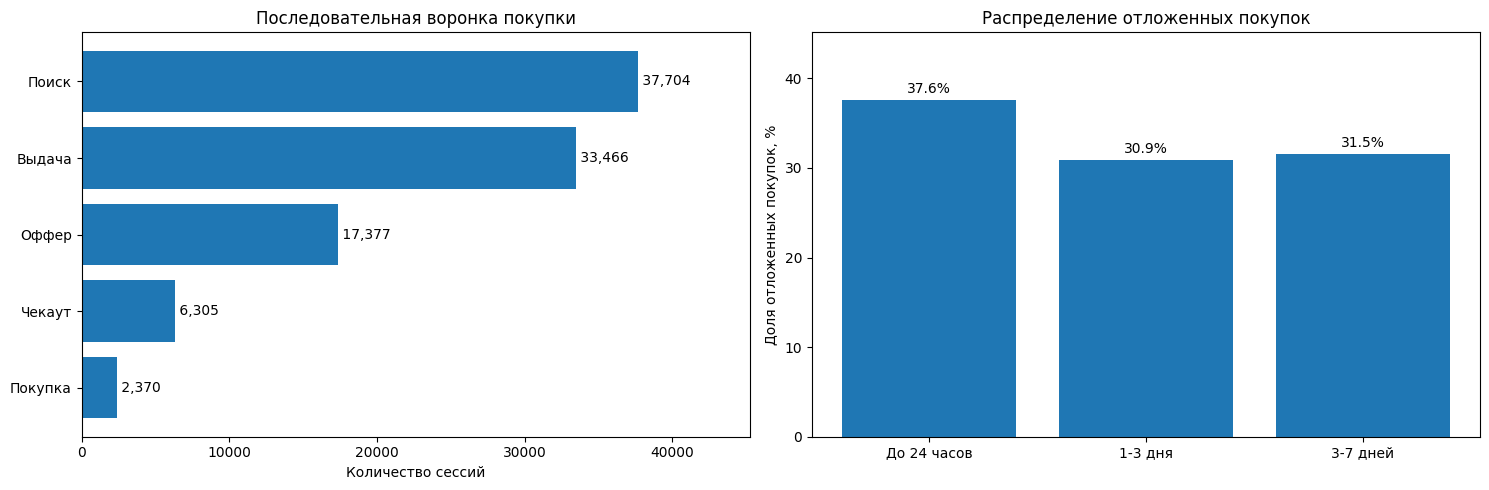

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

funnel_data = sequential_funnel['Сессии'].iloc[::-1]
axes[0].barh(funnel_data.index, funnel_data.values)
axes[0].set_title('Последовательная воронка покупки')
axes[0].set_xlabel('Количество сессий')
axes[0].set_xlim(0, funnel_data.max() * 1.2)

for i, value in enumerate(funnel_data.values):
    axes[0].text(value, i, f' {value:,}', va='center')

delay_data = delay_distribution['Доля, %']
bars = axes[1].bar(delay_data.index.astype(str), delay_data.values)
axes[1].bar_label(bars, fmt='%.1f%%', padding=3)
axes[1].set_title('Распределение отложенных покупок')
axes[1].set_ylabel('Доля отложенных покупок, %')
axes[1].set_ylim(0, delay_data.max() * 1.2)

plt.tight_layout()
fig.savefig('assets/avia_results.png', dpi=300, bbox_inches='tight')
plt.show()